**Problem 3b**

In [4]:
import numpy as np

Q = np.array([
    [-2, 2, 0, 0],
    [1, -3, 2, 0],
    [0, 2, -4, 2],
    [0, 0, 3, -3]
], dtype=float)

eigenvalues = np.linalg.eigvals(Q).real
eigenvalues = np.sort(eigenvalues)[::-1]

print("Eigenvalues:", np.round(eigenvalues, 4))
print("Sum:", np.sum(eigenvalues))
print("Trace:", np.trace(Q))

Eigenvalues: [-0.     -1.5107 -3.7108 -6.7785]
Sum: -12.000000000000004
Trace: -12.0


**Problem 3c**

Eigenvalues: [ 0.     -1.5107 -3.7108 -6.7785]
Second eigenvalue: -1.5107

Time when TV = 0.01: 2.898
ln(100) / |lambda_2|: 3.0483
Difference: -0.1504


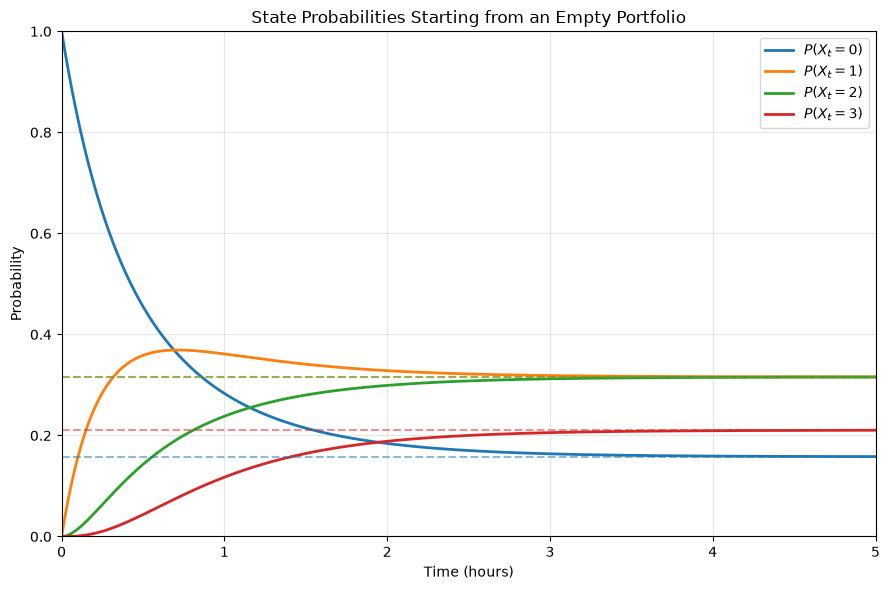

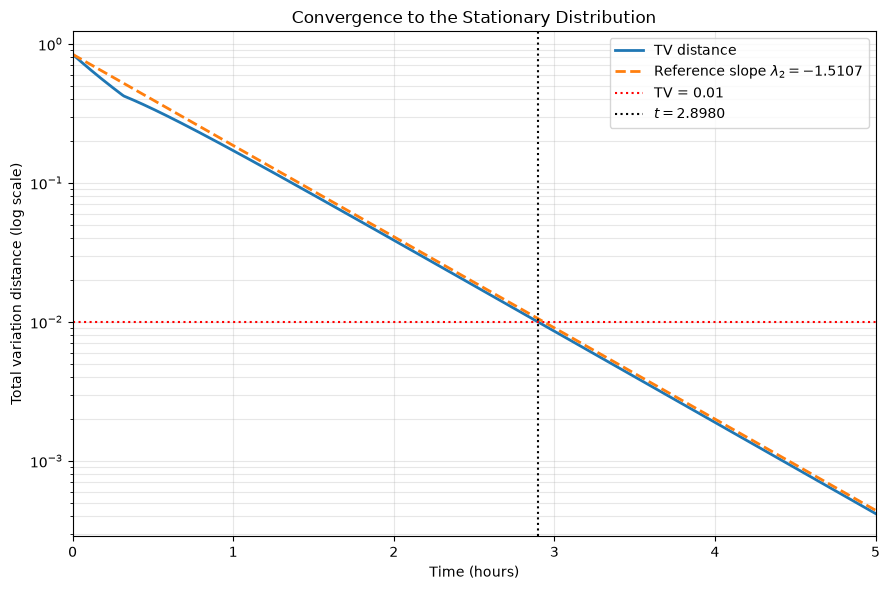


State probabilities and TV distance
 t       x0       x1       x2       x3       TV
0.0   1.0000   0.0000   0.0000   0.0000   0.8421
0.5   0.4553   0.3586   0.1428   0.0433   0.3401
1.0   0.2832   0.3614   0.2381   0.1174   0.1709
2.0   0.1842   0.3283   0.2991   0.1885   0.0387
3.0   0.1637   0.3186   0.3121   0.2056   0.0086
4.0   0.1592   0.3164   0.3150   0.2094   0.0019
5.0   0.1582   0.3159   0.3156   0.2103   0.0004


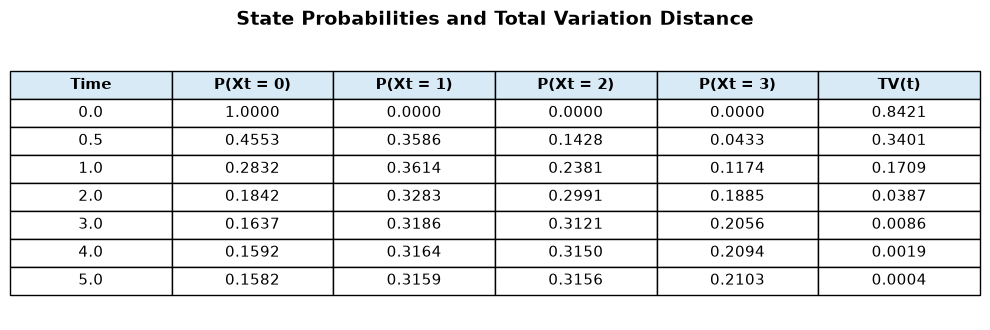

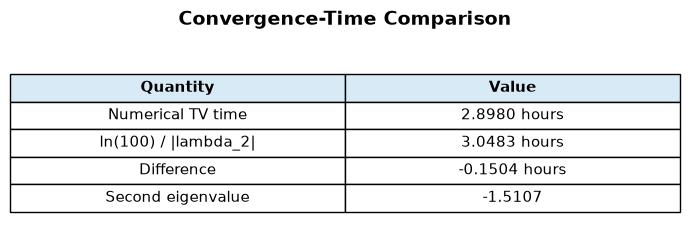

In [5]:
import numpy as np
import matplotlib.pyplot as plt
from scipy.linalg import expm
from scipy.optimize import brentq


Q = np.array([
    [-2,  2,  0,  0],
    [ 1, -3,  2,  0],
    [ 0,  2, -4,  2],
    [ 0,  0,  3, -3]
], dtype=float)

#Starting empty
x0 = np.array([1, 0, 0, 0], dtype=float)

#Stationary dist
pi = np.array([3/19, 6/19, 6/19, 4/19])


eigenvalues = np.sort(np.linalg.eigvals(Q).real)[::-1]
eigenvalues[np.abs(eigenvalues) < 1e-10] = 0

lambda2 = eigenvalues[1]

print("Eigenvalues:", np.round(eigenvalues, 4))
print("Second eigenvalue:", round(lambda2, 4))


def distribution(t):
    return x0 @ expm(t * Q)


def total_variation(t):
    xt = distribution(t)
    return 0.5 * np.sum(np.abs(xt - pi))


times = np.linspace(0, 5, 501)

probabilities = np.array([
    distribution(t) for t in times
])

tv_values = np.array([
    total_variation(t) for t in times
])


tv_time = brentq(
    lambda t: total_variation(t) - 0.01,
    0,
    5
)

eigenvalue_approximation = np.log(100) / abs(lambda2)

difference = tv_time - eigenvalue_approximation

print()
print("Time when TV = 0.01:", round(tv_time, 4))
print("ln(100) / |lambda_2|:", round(eigenvalue_approximation, 4))
print("Difference:", round(difference, 4))

#Plot!

plt.figure(figsize=(9, 6))

plt.plot(times, probabilities[:, 0],
         label=r"$P(X_t=0)$", linewidth=2)

plt.plot(times, probabilities[:, 1],
         label=r"$P(X_t=1)$", linewidth=2)

plt.plot(times, probabilities[:, 2],
         label=r"$P(X_t=2)$", linewidth=2)

plt.plot(times, probabilities[:, 3],
         label=r"$P(X_t=3)$", linewidth=2)

for i in range(4):
    plt.axhline(
        pi[i],
        color=f"C{i}",
        linestyle="--",
        alpha=0.5
    )

plt.xlabel("Time (hours)")
plt.ylabel("Probability")
plt.title("State Probabilities Starting from an Empty Portfolio")
plt.xlim(0, 5)
plt.ylim(0, 1)
plt.legend()
plt.grid(alpha=0.3)
plt.tight_layout()

plt.savefig(
    "3c_state_probabilities.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()





reference_line = tv_values[0] * np.exp(lambda2 * times)

plt.figure(figsize=(9, 6))

plt.semilogy(
    times,
    tv_values,
    linewidth=2,
    label="TV distance"
)

plt.semilogy(
    times,
    reference_line,
    linestyle="--",
    linewidth=2,
    label=fr"Reference slope $\lambda_2={lambda2:.4f}$"
)

plt.axhline(
    0.01,
    color="red",
    linestyle=":",
    label="TV = 0.01"
)

plt.axvline(
    tv_time,
    color="black",
    linestyle=":",
    label=fr"$t={tv_time:.4f}$"
)

plt.xlabel("Time (hours)")
plt.ylabel("Total variation distance (log scale)")
plt.title("Convergence to the Stationary Distribution")
plt.xlim(0, 5)
plt.legend()
plt.grid(alpha=0.3, which="both")
plt.tight_layout()

plt.savefig(
    "3c_tv_distance.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()


report_times = np.array([0, 0.5, 1, 2, 3, 4, 5])

table_rows = []

for t in report_times:
    xt = distribution(t)

    table_rows.append([
        t,
        xt[0],
        xt[1],
        xt[2],
        xt[3],
        total_variation(t)
    ])

table_rows = np.array(table_rows)

print()
print("State probabilities and TV distance")
print(" t       x0       x1       x2       x3       TV")

for row in table_rows:
    print(
        f"{row[0]:3.1f}   "
        f"{row[1]:.4f}   "
        f"{row[2]:.4f}   "
        f"{row[3]:.4f}   "
        f"{row[4]:.4f}   "
        f"{row[5]:.4f}"
    )




fig, ax = plt.subplots(figsize=(10, 3.4))
ax.axis("off")

column_labels = [
    "Time",
    "P(Xt = 0)",
    "P(Xt = 1)",
    "P(Xt = 2)",
    "P(Xt = 3)",
    "TV(t)"
]

formatted_rows = []

for row in table_rows:
    formatted_rows.append([
        f"{row[0]:.1f}",
        f"{row[1]:.4f}",
        f"{row[2]:.4f}",
        f"{row[3]:.4f}",
        f"{row[4]:.4f}",
        f"{row[5]:.4f}"
    ])

table = ax.table(
    cellText=formatted_rows,
    colLabels=column_labels,
    cellLoc="center",
    loc="center"
)

table.auto_set_font_size(False)
table.set_fontsize(11)
table.scale(1, 1.6)

for j in range(len(column_labels)):
    table[(0, j)].set_facecolor("#D9EAF7")
    table[(0, j)].set_text_props(weight="bold")

plt.title(
    "State Probabilities and Total Variation Distance",
    fontsize=14,
    weight="bold",
    pad=15
)

plt.tight_layout()

plt.savefig(
    "3c_probability_table.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()


comparison_rows = [
    ["Numerical TV time", f"{tv_time:.4f} hours"],
    [r"ln(100) / |lambda_2|",
     f"{eigenvalue_approximation:.4f} hours"],
    ["Difference", f"{difference:.4f} hours"],
    ["Second eigenvalue", f"{lambda2:.4f}"]
]

fig, ax = plt.subplots(figsize=(7, 2.6))
ax.axis("off")

comparison_table = ax.table(
    cellText=comparison_rows,
    colLabels=["Quantity", "Value"],
    cellLoc="center",
    loc="center"
)

comparison_table.auto_set_font_size(False)
comparison_table.set_fontsize(11)
comparison_table.scale(1, 1.7)

for j in range(2):
    comparison_table[(0, j)].set_facecolor("#D9EAF7")
    comparison_table[(0, j)].set_text_props(weight="bold")

plt.title(
    "Convergence-Time Comparison",
    fontsize=14,
    weight="bold",
    pad=15
)

plt.tight_layout()

plt.savefig(
    "3c_convergence_table.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()